In [98]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import time

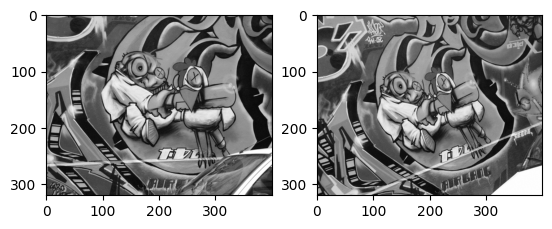

In [99]:
from pathlib import Path

image_dir = next(
    (path for path in (Path("assignment1/data/graf"), Path("data/graf")) if path.is_dir()),
    None,
)
if image_dir is None:
    raise FileNotFoundError("Could not find data/graf relative to the workspace or assignment1 directory")

im1 = cv.imread(str(image_dir / "img1.ppm"), cv.IMREAD_GRAYSCALE)
im2 = cv.imread(str(image_dir / "img2.ppm"), cv.IMREAD_GRAYSCALE)
if im1 is None or im2 is None:
    raise FileNotFoundError(f"Could not load img1.ppm and img2.ppm from {image_dir.resolve()}")

plt.subplot(1, 2, 1)
plt.imshow(im1, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(im2, cmap='gray')
plt.show()



Time taken to compute SIFT features: 0.0460 seconds
Number of keypoints in image 1: 501
Number of keypoints in image 2: 501


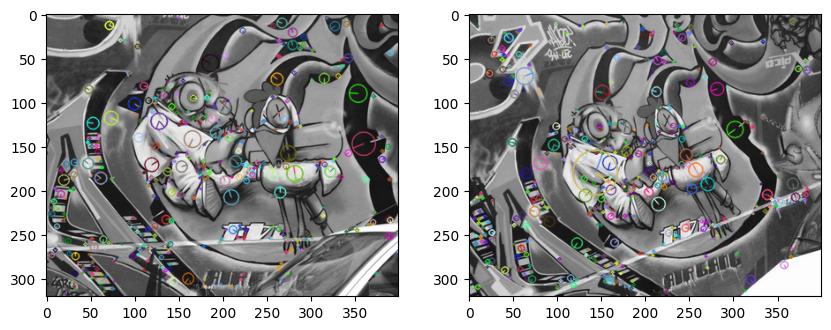

Time taken to compute FAST features: 0.0030 seconds
Number of keypoints in image 1 (FAST): 487
Number of keypoints in image 2 (FAST): 572


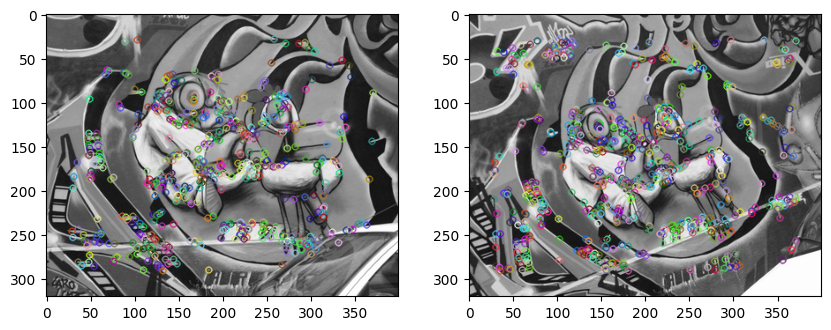

In [100]:
sift = cv.SIFT_create(nfeatures=500, nOctaveLayers=3, contrastThreshold=0.03, edgeThreshold=10, sigma=1.6)
start_time = time.time()
kp1, des1 = sift.detectAndCompute(im1, None)
kp2, des2 = sift.detectAndCompute(im2, None)
end_time = time.time()
print(f"Time taken to compute SIFT features: {end_time - start_time:.4f} seconds")
print(f"Number of keypoints in image 1: {len(kp1)}")
print(f"Number of keypoints in image 2: {len(kp2)}")

image_with_keypoints1 = cv.drawKeypoints(im1, kp1, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints2 = cv.drawKeypoints(im2, kp2, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_with_keypoints1, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(image_with_keypoints2, cmap='gray')
plt.show()


fast = cv.FastFeatureDetector_create(threshold=50, nonmaxSuppression=True)
start_time = time.time()
kp1_fast = fast.detect(im1, None)
kp2_fast = fast.detect(im2, None)

brief = cv.xfeatures2d.BriefDescriptorExtractor_create()
kp1_fast, des1_fast = brief.compute(im1, kp1_fast)
kp2_fast, des2_fast = brief.compute(im2, kp2_fast)
end_time = time.time()
print(f"Time taken to compute FAST features: {end_time - start_time:.4f} seconds")
print(f"Number of keypoints in image 1 (FAST): {len(kp1_fast)}")
print(f"Number of keypoints in image 2 (FAST): {len(kp2_fast)}")

image_with_keypoints1_fast = cv.drawKeypoints(im1, kp1_fast, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
image_with_keypoints2_fast = cv.drawKeypoints(im2, kp2_fast, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_with_keypoints1_fast, cmap='gray')
plt.subplot(1, 2, 2)
plt.imshow(image_with_keypoints2_fast, cmap='gray')
plt.show()  


Time taken to match and verify features: 0.0040 seconds
Mutual ratio-test matches: 220; geometrically consistent: 219


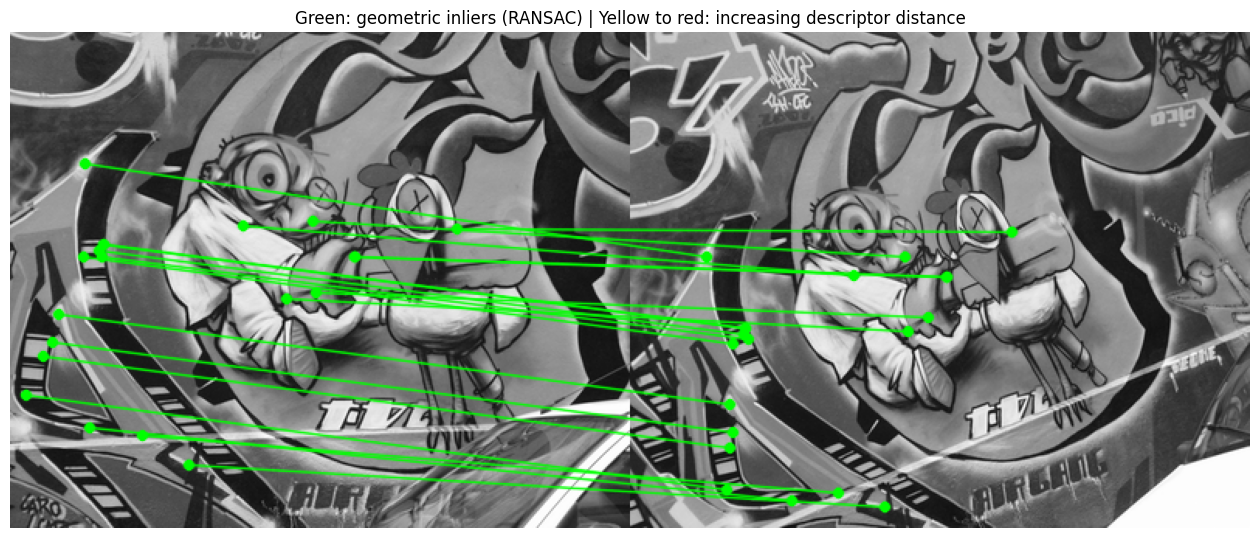

FAST matches after reciprocal + RANSAC: 11


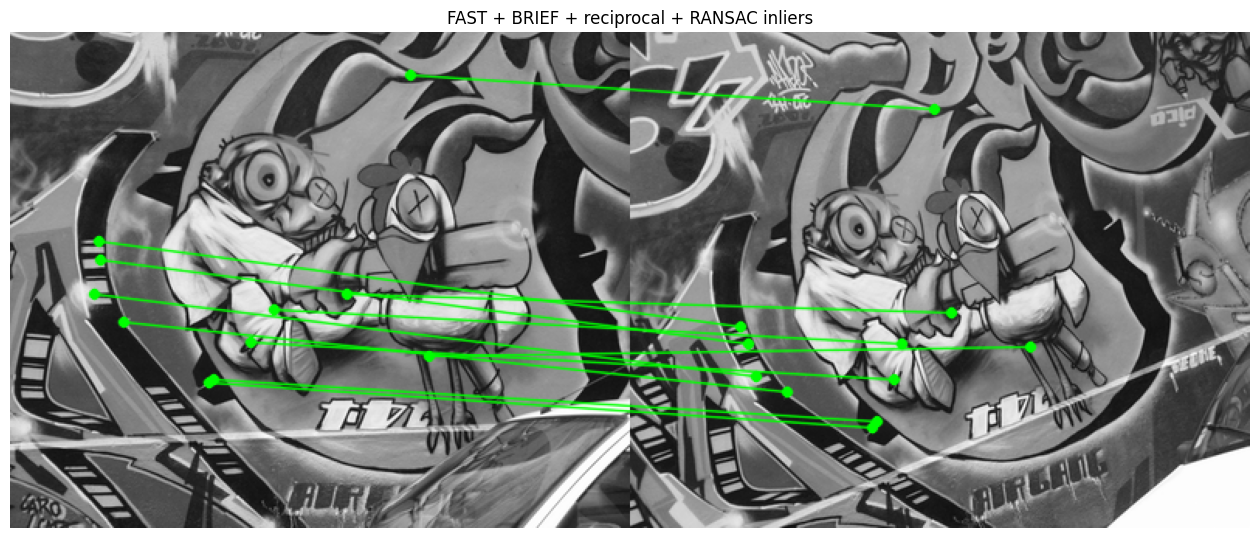

In [ ]:
### [SIFT]

matcher = cv.BFMatcher(cv.NORM_L2)
ratio_threshold = 0.75
start_time = time.time()
forward = matcher.knnMatch(des1, des2, k=2)
reverse = matcher.knnMatch(des2, des1, k=2)

# Mutual ratio-test matches
forward_good = {
    m.queryIdx: m
    for pair in forward if len(pair) == 2
    for m, n in [pair]
    if m.distance < ratio_threshold * n.distance
}
reverse_good = {
    m.queryIdx: m
    for pair in reverse if len(pair) == 2
    for m, n in [pair]
    if m.distance < ratio_threshold * n.distance
}
# Find matches that are consistent in both directions
matches = [
    match for match in forward_good.values()
    if match.trainIdx in reverse_good
    and reverse_good[match.trainIdx].trainIdx == match.queryIdx
]
matches.sort(key=lambda match: match.distance)
if len(matches) < 4:
    raise ValueError(f"Only {len(matches)} reliable matches found; at least 4 are needed for geometric verification")

points1 = np.float32([kp1[match.queryIdx].pt for match in matches]).reshape(-1, 1, 2)
points2 = np.float32([kp2[match.trainIdx].pt for match in matches]).reshape(-1, 1, 2)
_, inlier_mask = cv.findHomography(points1, points2, cv.RANSAC, 5.0)
if inlier_mask is None:
    raise RuntimeError("RANSAC could not find a consistent geometric transform for the matches")
inliers = inlier_mask.ravel().astype(bool)
end_time = time.time()
print(f"Time taken to match and verify features: {end_time - start_time:.4f} seconds")
print(f"Mutual ratio-test matches: {len(matches)}; geometrically consistent: {int(inliers.sum())}")

max_matches = 20
matches_to_draw = matches[:max_matches]
draw_inliers = inliers[:max_matches]
distances = np.array([match.distance for match in matches_to_draw], dtype=np.float32)
distance_span = float(np.ptp(distances)) if len(distances) else 0.0
height = max(im1.shape[0], im2.shape[0])
width1 = im1.shape[1]
image_matches = np.zeros((height, width1 + im2.shape[1], 3), dtype=np.uint8)
image_matches[:im1.shape[0], :width1] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
image_matches[:im2.shape[0], width1:] = cv.cvtColor(im2, cv.COLOR_GRAY2BGR)

for index, match in enumerate(matches_to_draw):
    point1 = tuple(np.round(kp1[match.queryIdx].pt).astype(int))
    point2 = tuple(np.round(kp2[match.trainIdx].pt).astype(int) + np.array([width1, 0]))
    if draw_inliers[index]:
        color = (0, 255, 0)
    else:
        relative_distance = (match.distance - distances.min()) / distance_span if distance_span else 0.0
        color = (0, int(255 * (1 - relative_distance)), 255)
    cv.line(image_matches, point1, point2, color, 1, cv.LINE_AA)
    cv.circle(image_matches, point1, 3, color, -1, cv.LINE_AA)
    cv.circle(image_matches, point2, 3, color, -1, cv.LINE_AA)
    
print(f"Number of SIFT matches drawn: {len(matches_to_draw)}")

plt.figure(figsize=(16, 8))
plt.imshow(cv.cvtColor(image_matches, cv.COLOR_BGR2RGB))
plt.title("Green: geometric inliers (RANSAC) | Yellow to red: increasing descriptor distance")
plt.axis("off")
plt.show()

### [Fast]


bf = cv.BFMatcher(cv.NORM_HAMMING)
matches_fast = bf.knnMatch(des1_fast, des2_fast, k=2)


good_matches_fast = []
for m, n in matches_fast:
    if m.distance < ratio_threshold * n.distance:
        good_matches_fast.append(m)

rev_matches_fast = bf.knnMatch(des2_fast, des1_fast, k=2)
good_rev_matches_fast = []
for m, n in rev_matches_fast:
    if m.distance < ratio_threshold * n.distance:
        good_rev_matches_fast.append(m)

reverse_good_fast = {m.queryIdx: m for m in good_rev_matches_fast}

mutual_matches_fast = [
    match for match in good_matches_fast
    if match.trainIdx in reverse_good_fast
    and reverse_good_fast[match.trainIdx].trainIdx == match.queryIdx
]

if len(mutual_matches_fast) < 8:
    raise ValueError(
        f"Only {len(mutual_matches_fast)} reliable FAST matches found; at least 8 are needed for strong geometric verification"
    )

mutual_matches_fast.sort(key=lambda match: match.distance)


pts1_fast = np.float32([kp1_fast[m.queryIdx].pt for m in mutual_matches_fast]).reshape(-1, 1, 2)
pts2_fast = np.float32([kp2_fast[m.trainIdx].pt for m in mutual_matches_fast]).reshape(-1, 1, 2)

_, inlier_mask_fast = cv.findHomography(pts1_fast, pts2_fast, cv.RANSAC, 5.0)

if inlier_mask_fast is None:
    raise RuntimeError("RANSAC could not find a consistent geometric transform for FAST matches")

inliers_fast = inlier_mask_fast.ravel().astype(bool)

mutual_matches_fast = [m for m, keep in zip(mutual_matches_fast, inliers_fast) if keep]

if len(mutual_matches_fast) < 4:
    raise ValueError(f"Only {len(mutual_matches_fast)} inlier matches remain; at least 4 needed.")

print(f"FAST matches after reciprocal + RANSAC: {len(mutual_matches_fast)}")

# 8) Desenhar
max_matches_fast = 20
matches_to_draw_fast = mutual_matches_fast[:max_matches_fast]
height_fast = max(im1.shape[0], im2.shape[0])
width1_fast = im1.shape[1]
image_matches_fast = np.zeros((height_fast, width1_fast + im2.shape[1], 3), dtype=np.uint8)
image_matches_fast[:im1.shape[0], :width1_fast] = cv.cvtColor(im1, cv.COLOR_GRAY2BGR)
image_matches_fast[:im2.shape[0], width1_fast:] = cv.cvtColor(im2, cv.COLOR_GRAY2BGR)

for match in matches_to_draw_fast:
    pt1 = tuple(np.round(kp1_fast[match.queryIdx].pt).astype(int))
    pt2 = tuple(np.round(kp2_fast[match.trainIdx].pt).astype(int) + np.array([width1_fast, 0]))
    cv.line(image_matches_fast, pt1, pt2, (0, 255, 0), 1, cv.LINE_AA)
    cv.circle(image_matches_fast, pt1, 3, (0, 255, 0), -1, cv.LINE_AA)
    cv.circle(image_matches_fast, pt2, 3, (0, 255, 0), -1, cv.LINE_AA)
    
print(f"Number of FAST matches drawn: {len(matches_to_draw_fast)}")

plt.figure(figsize=(16, 8))
plt.imshow(cv.cvtColor(image_matches_fast, cv.COLOR_BGR2RGB))
plt.title("FAST + BRIEF + reciprocal + RANSAC inliers")
plt.axis("off")
plt.show()


